### Agenda

1. **Conectarse con Google Drive**
2. **Importar librerías necesarias**
3. **Cargar datasets**
    * **3.1** timeline_frames.csv
    * **3.2** Diccionario de Datos
    * **3.3** timeline_events.csv
4. **Filtrar al jugador analizado**
5. **Filtrar remakes**
6. **Preparar los datos**
    * **6.1** Tabla resumen por partida (`df_partidas`)
7. **Resumen general**
8. **Rendimiento**
    * **8.1** Winrate (por tiempo jugado, gráfico radial)
    * **8.2** KDA
    * **8.3** CS por minuto
    * **8.4** Oro por minuto
    * **8.5** Daño
    * **8.6** Visión (wards)
    * **8.7** Kills
    * **8.8** Asistencias
    * **8.9** Gráfico radial
9. **Campeones más jugados**
    * **9.1** Winrate de los 2 campeones más jugados
10. **Posiciones más jugadas**
11. **Winrate por campeón**

---
**Análisis anteriores (en pausa)**, al final del notebook: mapa de calor, muertes / winrate / kills por fase, oro por minuto, consistencia, pool de campeones y posiciones.

###1. Conectarse con google drive




In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###2. Importar librerias necesarias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import os
%matplotlib inline

###3. Cargar datasets

###3.1 timeline_frames.csv

In [ ]:
ruta_dataset = "/content/drive/MyDrive/Ciencia De Datos/lol/timeline_frames.csv"
#ruta_dataset = "/content/drive/MyDrive/U/Fundamentos de Ciencia de Datos/Lol/timeline_frames.csv"


print(f"Dataset cargado desde: {ruta_dataset}")
timeline_frames = pd.read_csv(ruta_dataset)
print(f"Frames totales cargados: {len(timeline_frames)}")
timeline_frames.head()

Dataset cargado desde: /content/drive/MyDrive/Ciencia De Datos/lol/timeline_frames.csv
Frames totales cargados: 22900


,match_id,minuto,timestamp_ms,participant_id,es_jugador,riot_id,champion,position,team_id,win,...,dmg_magicDamageTaken,dmg_physicalDamageDone,dmg_physicalDamageDoneToChampions,dmg_physicalDamageTaken,dmg_totalDamageDone,dmg_totalDamageDoneToChampions,dmg_totalDamageTaken,dmg_trueDamageDone,dmg_trueDamageDoneToChampions,dmg_trueDamageTaken
0,LA1_1695464615,0,0,1,False,javyo#LAN,Pantheon,TOP,100,True,...,0,0,0,0,0,0,0,0,0,0
1,LA1_1695464615,0,0,2,False,BuuuXD#LAN,Nasus,JUNGLE,100,True,...,0,0,0,0,0,0,0,0,0,0
2,LA1_1695464615,0,0,3,False,Satipp#9548,Akali,MIDDLE,100,True,...,0,0,0,0,0,0,0,0,0,0
3,LA1_1695464615,0,0,4,False,joseberzeker#LAN,MissFortune,BOTTOM,100,True,...,0,0,0,0,0,0,0,0,0,0
4,LA1_1695464615,0,0,5,False,Killjoy99#LAN,Morgana,UTILITY,100,True,...,0,0,0,0,0,0,0,0,0,0


###3.2 Diccionario de Datos
Cada fila es una "foto" de un jugador al inicio de cada minuto de la partida (10 jugadores por minuto). La fila del jugador analizado se identifica con `es_jugador = True`.

| Columna             | Descripcion
|:--------------------|:---------------------------------------------
| **match_id**        | Identificador unico de la partida
| **minuto**          | Minuto de la partida al que corresponde el frame
| **timestamp_ms**    | Tiempo exacto del frame en milisegundos desde el inicio
| **participant_id**  | Identificador del participante en la partida (1 a 10)
| **es_jugador**      | True si la fila corresponde al jugador analizado
| **riot_id**         | Nombre de invocador (Riot ID) del participante
| **champion**        | Campeon utilizado por el participante
| **position**        | Posicion/rol jugado (TOP, JUNGLE, MIDDLE, BOTTOM, UTILITY)
| **team_id**         | Equipo del participante (100 = azul, 200 = rojo)
| **win**             | Resultado de la partida para el participante (True = Victoria)
| **level**           | Nivel del campeon en ese minuto
| **xp**              | Experiencia acumulada
| **total_gold**      | Oro total ganado hasta ese minuto
| **current_gold**    | Oro disponible sin gastar
| **gold_per_second** | Oro generado por segundo
| **minions**         | Subditos asesinados
| **jungle_minions**  | Monstruos de la jungla asesinados
| **cs_total**        | Total de CS (subditos + monstruos de jungla)
| **time_enemy_controlled** | Tiempo que el participante mantuvo controlados a enemigos (CC)
| **pos_x**           | Coordenada X del participante en el mapa
| **pos_y**           | Coordenada Y del participante en el mapa
| **champ_health**    | Vida actual del campeon
| **champ_healthMax** | Vida maxima del campeon
| **champ_healthRegen** | Regeneracion de vida
| **champ_power**     | Recurso actual (mana, energia, etc.)
| **champ_powerMax**  | Recurso maximo
| **champ_powerRegen**| Regeneracion de recurso
| **champ_attackDamage** | Dano de ataque
| **champ_abilityPower** | Poder de habilidad
| **champ_attackSpeed**  | Velocidad de ataque
| **champ_armor**     | Armadura
| **champ_magicResist** | Resistencia magica
| **champ_movementSpeed** | Velocidad de movimiento
| **champ_abilityHaste** | Aceleracion de habilidad
| **champ_cooldownReduction** | Reduccion de enfriamiento
| **champ_ccReduction** | Reduccion de control de masas (tenacidad)
| **champ_armorPen / armorPenPercent / bonusArmorPenPercent** | Penetracion de armadura (plana, porcentual y de armadura bonus)
| **champ_magicPen / magicPenPercent / bonusMagicPenPercent** | Penetracion magica (plana, porcentual y bonus)
| **champ_lifesteal / physicalVamp / spellVamp / omnivamp** | Robo de vida (ataques, vampirismo fisico, de hechizos y omnivampirismo)
| **dmg_totalDamageDone** | Dano total infligido
| **dmg_totalDamageDoneToChampions** | Dano total infligido a campeones
| **dmg_totalDamageTaken** | Dano total recibido
| **dmg_physicalDamageDone / ...ToChampions / ...Taken** | Dano fisico infligido, a campeones y recibido
| **dmg_magicDamageDone / ...ToChampions / ...Taken** | Dano magico infligido, a campeones y recibido
| **dmg_trueDamageDone / ...ToChampions / ...Taken** | Dano verdadero infligido, a campeones y recibido

###3.3 timeline_events.csv
Eventos de la partida (kills, wards, objetivos, etc.), con una fila por evento.

In [ ]:
ruta_eventos = "/content/drive/MyDrive/Ciencia De Datos/lol/timeline_events.csv"
#ruta_eventos = "/content/drive/MyDrive/U/Fundamentos de Ciencia de Datos/Lol/timeline_events.csv"

print(f"Dataset cargado desde: {ruta_eventos}")
timeline_events = pd.read_csv(ruta_eventos)
print(f"Eventos totales cargados: {len(timeline_events)}")
timeline_events.head()

Dataset cargado desde: /content/drive/MyDrive/Ciencia De Datos/lol/timeline_events.csv
Eventos totales cargados: 80998


,match_id,minuto,timestamp_ms,segundo_partida,type,involucra_jugador,itemId,participantId,levelUpType,skillSlot,...,monsterSubType,monsterType,multiKillLength,gameId,winningTeam,buildingType,towerType,name,actualStartTime,transformType
0,LA1_1695464615,0,0,0.0,PAUSE_END,False,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LA1_1695464615,0,0,0.0,ITEM_PURCHASED,False,3865.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LA1_1695464615,0,0,0.0,ITEM_PURCHASED,False,3865.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LA1_1695464615,1,4154,4.2,SKILL_LEVEL_UP,True,NaN,10.0,NORMAL,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LA1_1695464615,1,4755,4.8,SKILL_LEVEL_UP,False,NaN,1.0,NORMAL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


###3.4 Diccionario de Datos (timeline_events)
Cada fila es un evento de la partida. Según el tipo (`type`), solo se llenan las columnas que le corresponden; el resto queda vacío.

| Columna             | Descripcion
|:--------------------|:---------------------------------------------
| **match_id**        | Identificador unico de la partida
| **minuto**          | Minuto de la partida en que ocurrio el evento
| **timestamp_ms**    | Tiempo exacto del evento en milisegundos desde el inicio
| **segundo_partida** | Segundo de la partida en que ocurrio el evento
| **type**            | Tipo de evento (CHAMPION_KILL, WARD_PLACED, WARD_KILL, ITEM_PURCHASED, SKILL_LEVEL_UP, LEVEL_UP, BUILDING_KILL, ELITE_MONSTER_KILL, TURRET_PLATE_DESTROYED, etc.)
| **involucra_jugador** | True si el evento involucra al jugador analizado
| **participantId / participantId_champion** | Participante que realiza el evento y su campeon
| **itemId / afterId / beforeId** | Objeto comprado, vendido o destruido; objeto resultante y anterior (ITEM_UNDO)
| **goldGain**        | Oro devuelto o ganado por el evento
| **levelUpType / skillSlot / level** | Tipo de subida de nivel, habilidad mejorada y nivel alcanzado
| **creatorId / creatorId_champion** | Participante que coloca la ward y su campeon
| **wardType**        | Tipo de ward colocada
| **killerId / killerId_champion / killerTeamId** | Participante, campeon y equipo que realiza la kill
| **victimId / victimId_champion** | Participante y campeon que muere
| **assistingParticipantIds** | Lista de participantes que asisten en la kill
| **bounty / shutdownBounty / killStreakLength / multiKillLength** | Recompensa de la kill, recompensa por cortar racha, racha de kills y kills multiples
| **killType**        | Tipo de kill
| **victimTeamfightDamageDealt / victimTeamfightDamageReceived** | Dano que la victima inflige y recibe en la pelea
| **pos_x / pos_y**   | Coordenadas del evento en el mapa
| **laneType / buildingType / towerType** | Linea y tipo de estructura destruida
| **teamId**          | Equipo asociado al evento
| **monsterType / monsterSubType** | Tipo y subtipo de monstruo epico (dragon, barón, etc.)
| **gameId / winningTeam / actualStartTime / name / transformType** | Datos de fin de partida, pausa y eventos especiales

###3.5 matches_2026.csv
Resumen de cada partida (una fila por partida): fecha y hora, cola, resultado y estadísticas finales del jugador.

In [249]:
ruta_matches = "/content/drive/MyDrive/Ciencia De Datos/lol/matches_2026.csv"

print(f"Dataset cargado desde: {ruta_matches}")
matches_2026 = pd.read_csv(ruta_matches)
matches_2026["fecha"] = pd.to_datetime(matches_2026["fecha"])
print(f"Partidas totales cargadas: {len(matches_2026)}")
matches_2026.head()

Dataset cargado desde: /content/drive/MyDrive/Ciencia De Datos/lol/matches_2026.csv
Partidas totales cargadas: 78


,match_id,fecha,duracion_minutos,game_version,queue_id,cola,remake,equipo,champion,position,...,vision_score,wards_placed,wards_killed,item_0,item_1,item_2,item_3,item_4,item_5,item_6
0,LA1_1751158082,2026-09-25 08:17:13.447,11.30,16.19.821.7343,420,Ranked Solo/Duo,False,azul,Nautilus,UTILITY,...,7,3,0,Brújula Rúnica,Armadura de Tela,Cinturón de Gigante,0,0,0,Lente del Oráculo
1,LA1_1749525517,2026-09-18 01:02:55.129,37.67,16.18.817.5716,420,Ranked Solo/Duo,False,azul,Thresh,UTILITY,...,60,25,5,Trineo del Solsticio,Presagio de Randuin,Corazón de Hielo,Botas de Rapidez,Capa de Negatrones,Cristal de Rubí,Lente del Oráculo
2,LA1_1749123417,2026-09-16 13:28:23.480,33.40,16.18.817.5716,420,Ranked Solo/Duo,False,rojo,Nautilus,UTILITY,...,59,25,5,Trineo del Solsticio,Presagio de Randuin,Punteras de Acero Revestidas,Rukerno Kaénico,Capa de Negatrones,0,Lente del Oráculo
3,LA1_1749099056,2026-09-16 09:50:38.644,30.30,16.18.817.5716,420,Ranked Solo/Duo,False,rojo,Nautilus,UTILITY,...,55,21,5,Trineo del Solsticio,Presagio de Randuin,Poción Reutilizable,Botas de Rapidez,Rukerno Kaénico,Capa de Negatrones,Lente del Oráculo
4,LA1_1749092733,2026-09-16 09:10:23.337,28.35,16.18.817.5716,420,Ranked Solo/Duo,False,rojo,Thresh,UTILITY,...,51,21,6,Trineo del Solsticio,Presagio de Randuin,Botas de Mercurio,Rukerno Kaénico,0,0,Lente del Oráculo


###3.6 Diccionario de Datos (matches_2026)
Cada fila es una partida jugada por el jugador analizado.

| Columna             | Descripcion
|:--------------------|:---------------------------------------------
| **match_id**        | Identificador unico de la partida (une con los otros datasets)
| **fecha**           | Fecha y hora en que se jugo la partida
| **duracion_minutos**| Duracion de la partida en minutos
| **game_version**    | Version del juego
| **queue_id / cola** | Identificador y nombre de la cola (Ranked Solo/Duo)
| **remake**          | True si la partida se reinicio (remake)
| **equipo**          | Equipo del jugador (azul o rojo)
| **champion**        | Campeon usado
| **position**        | Posicion jugada (TOP, JUNGLE, MIDDLE, BOTTOM, UTILITY)
| **win**             | Resultado (True = Victoria)
| **kills / deaths / assists** | Asesinatos, muertes y asistencias
| **kda**             | (kills + assists) / deaths
| **cs_por_min**      | CS por minuto
| **gold_earned / gold_por_min** | Oro total ganado y oro por minuto
| **champ_level**     | Nivel final del campeon
| **damage_dealt / damage_taken** | Dano infligido a campeones y dano recibido
| **curacion_total / curacion_a_aliados / escudos_a_aliados** | Curacion propia, curacion a aliados y escudos a aliados
| **pociones_consumidas** | Pociones consumidas
| **hechizo_1 / hechizo_2** | Hechizos de invocador
| **hechizo_1_usos / hechizo_2_usos / uso_curar** | Veces que uso cada hechizo (y Curar)
| **vision_score**    | Puntaje de vision
| **wards_placed / wards_killed** | Wards colocadas y destruidas
| **item_0 ... item_6** | Objetos al final de la partida (item_6 = trinket)

###4. Filtrar al jugador analizado
El dataset trae los 10 participantes de cada partida. Nos quedamos únicamente con las filas donde `es_jugador = True`.

In [ ]:
# Copia filtrada: el dataset original (timeline_frames) queda intacto
df_jugador = timeline_frames[timeline_frames["es_jugador"]].copy().reset_index(drop=True)

print(f"Filas antes del filtro:   {len(timeline_frames)}")
print(f"Filas después del filtro: {len(df_jugador)}")
print(f"Partidas: {df_jugador['match_id'].nunique()}")

# Verificación: debe haber un solo frame por partida y minuto
duplicados = df_jugador.duplicated(subset=["match_id", "minuto"]).sum()
print(f"Frames duplicados (match_id, minuto): {duplicados}")

df_jugador.head()

Filas antes del filtro:   22900
Filas después del filtro: 2290
Partidas: 78
Frames duplicados (match_id, minuto): 0


,match_id,minuto,timestamp_ms,participant_id,es_jugador,riot_id,champion,position,team_id,win,...,dmg_magicDamageTaken,dmg_physicalDamageDone,dmg_physicalDamageDoneToChampions,dmg_physicalDamageTaken,dmg_totalDamageDone,dmg_totalDamageDoneToChampions,dmg_totalDamageTaken,dmg_trueDamageDone,dmg_trueDamageDoneToChampions,dmg_trueDamageTaken
0,LA1_1695464615,0,0,10,True,Sopa de pescado#BRY,Taric,UTILITY,200,False,...,0,0,0,0,0,0,0,0,0,0
1,LA1_1695464615,1,60004,10,True,Sopa de pescado#BRY,Taric,UTILITY,200,False,...,0,0,0,0,0,0,0,0,0,0
2,LA1_1695464615,2,120020,10,True,Sopa de pescado#BRY,Taric,UTILITY,200,False,...,107,165,0,385,615,0,503,335,0,10
3,LA1_1695464615,3,180033,10,True,Sopa de pescado#BRY,Taric,UTILITY,200,False,...,107,222,0,594,696,0,711,359,0,10
4,LA1_1695464615,4,240060,10,True,Sopa de pescado#BRY,Taric,UTILITY,200,False,...,107,222,0,743,696,0,861,359,0,10


###5. Filtrar remakes
Se excluyen las partidas que se reiniciaron (remakes). Se detectan por su duración: una partida de menos de 5 minutos no se llegó a jugar.

In [ ]:
# Duración de cada partida = timestamp del último frame
duracion = df_jugador.groupby("match_id")["timestamp_ms"].max() / 60000
remakes = duracion[duracion < 5].index

print(f"Partidas totales:        {len(duracion)}")
print(f"Remakes (< 5 min):       {len(remakes)}")

df_jugador = df_jugador[~df_jugador["match_id"].isin(remakes)].reset_index(drop=True)

print(f"Partidas jugadas:        {df_jugador['match_id'].nunique()}")
print(f"Frames del jugador:      {len(df_jugador)}")

Partidas totales:        78
Remakes (< 5 min):       8
Partidas jugadas:        70
Frames del jugador:      2266


###6. Preparar los datos

In [ ]:
# Copiar para dejar df_jugador (sección 4.1) intacto
df_frames = df_jugador.copy()
print(f"Frames del jugador: {len(df_frames)} | Partidas: {df_frames['match_id'].nunique()}")

Frames del jugador: 2266 | Partidas: 70


In [ ]:
# Revisar nulos y eliminar frames duplicados (un frame por partida y minuto)
nulos = df_frames.isna().sum()
print("Columnas con valores nulos:")
print(nulos[nulos > 0] if (nulos > 0).any() else "Ninguna")

antes = len(df_frames)
df_frames = df_frames.drop_duplicates(subset=["match_id", "minuto"]).reset_index(drop=True)
print(f"Duplicados eliminados: {antes - len(df_frames)}")

Columnas con valores nulos:
Ninguna
Duplicados eliminados: 0


In [ ]:
# Convertir el tiempo de milisegundos a segundos
df_frames["segundos"] = df_frames["timestamp_ms"] / 1000

In [ ]:
# Orden cronológico dentro de cada partida
df_frames = df_frames.sort_values(["match_id", "minuto"]).reset_index(drop=True)

In [ ]:
# Variables derivadas
# Vida como % de la vida máxima y cambio respecto al minuto anterior
df_frames["vida_pct"] = df_frames["champ_health"] / df_frames["champ_healthMax"] * 100
df_frames["delta_vida_pct"] = df_frames.groupby("match_id")["vida_pct"].diff()

# Fase de la partida
df_frames["fase"] = pd.cut(
    df_frames["minuto"],
    bins=[-1, 14, 25, 200],
    labels=["Early (0-14)", "Mid (15-25)", "Late (26+)"]
)

df_frames[["match_id", "minuto", "segundos", "vida_pct", "delta_vida_pct", "fase"]].head()

,match_id,minuto,segundos,vida_pct,delta_vida_pct,fase
0,LA1_1695464615,0,0.000,100.000000,NaN,Early (0-14)
1,LA1_1695464615,1,60.004,100.000000,0.000000,Early (0-14)
2,LA1_1695464615,2,120.020,43.765903,-56.234097,Early (0-14)
3,LA1_1695464615,3,180.033,41.657208,-2.108696,Early (0-14)
4,LA1_1695464615,4,240.060,100.000000,58.342792,Early (0-14)


###6.1 Tabla resumen por partida (`df_partidas`)
Una fila por partida, construida con `timeline_frames` (campeón, posición, resultado, duración, oro, CS y daño del último frame) y `timeline_events` (kills, muertes, asistencias y wards del jugador). Es la base de las secciones de resumen general y rendimiento.

In [ ]:
import ast

# Eventos necesarios para kills, muertes, asistencias y wards del jugador
ev = pd.read_csv(
    "/content/drive/MyDrive/Ciencia De Datos/lol/timeline_events.csv",
    usecols=["match_id", "type", "killerId", "victimId", "assistingParticipantIds", "creatorId"]
)

# participant_id del jugador analizado en cada partida
pid = (df_frames.drop_duplicates("match_id")[["match_id", "participant_id"]]
       .rename(columns={"participant_id": "pid"}))

# --- Kills / muertes / asistencias (CHAMPION_KILL) ---
k = ev[ev["type"] == "CHAMPION_KILL"].merge(pid, on="match_id")
k["asistio"] = [
    (p in ast.literal_eval(a)) if isinstance(a, str) else False
    for p, a in zip(k["pid"], k["assistingParticipantIds"])
]
kills   = k[k["killerId"] == k["pid"]].groupby("match_id").size()
deaths  = k[k["victimId"] == k["pid"]].groupby("match_id").size()
assists = k[k["asistio"]].groupby("match_id").size()

# --- Wards colocados / destruidos por el jugador ---
wp = ev[ev["type"] == "WARD_PLACED"].merge(pid, on="match_id")
wk = ev[ev["type"] == "WARD_KILL"].merge(pid, on="match_id")
wards_placed = wp[wp["creatorId"] == wp["pid"]].groupby("match_id").size()
wards_killed = wk[wk["killerId"] == wk["pid"]].groupby("match_id").size()

# --- Totales de la partida: último frame de cada partida ---
ultimo = (df_frames.sort_values(["match_id", "minuto"])
          .groupby("match_id").last()
          [["champion", "position", "team_id", "win", "timestamp_ms",
            "total_gold", "cs_total", "dmg_totalDamageDoneToChampions", "dmg_totalDamageTaken"]])

df_partidas = ultimo.rename(columns={
    "dmg_totalDamageDoneToChampions": "damage_dealt",
    "dmg_totalDamageTaken": "damage_taken",
    "total_gold": "gold_earned",
})
df_partidas["duracion_minutos"] = df_partidas["timestamp_ms"] / 60000
for nombre, serie in [("kills", kills), ("deaths", deaths), ("assists", assists),
                      ("wards_placed", wards_placed), ("wards_killed", wards_killed)]:
    df_partidas[nombre] = serie.reindex(df_partidas.index).fillna(0).astype(int)

# Métricas derivadas
df_partidas["kda"] = (df_partidas["kills"] + df_partidas["assists"]) / df_partidas["deaths"].clip(lower=1)
df_partidas["cs_por_min"] = df_partidas["cs_total"] / df_partidas["duracion_minutos"]
df_partidas["gold_por_min"] = df_partidas["gold_earned"] / df_partidas["duracion_minutos"]
df_partidas = df_partidas.drop(columns="timestamp_ms").reset_index()

print(f"Partidas: {len(df_partidas)}")
df_partidas.head()

Partidas: 70


,match_id,champion,position,team_id,win,gold_earned,cs_total,damage_dealt,damage_taken,duracion_minutos,kills,deaths,assists,wards_placed,wards_killed,kda,cs_por_min,gold_por_min
0,LA1_1695464615,Taric,UTILITY,200,False,7991,33,3528,29417,31.666533,1,8,7,13,6,1.000000,1.042110,252.348431
1,LA1_1695732552,Senna,UTILITY,200,False,13435,42,22260,27879,36.488350,5,8,16,20,14,2.625000,1.151052,368.199713
2,LA1_1695732861,TahmKench,UTILITY,200,True,10352,71,12543,31015,29.341133,1,3,9,17,11,3.333333,2.419811,352.815274
3,LA1_1695735372,TahmKench,UTILITY,100,True,11327,40,16983,43341,38.767950,6,4,4,28,13,2.500000,1.031780,292.174335
4,LA1_1697573283,Leblanc,UTILITY,200,True,10960,57,15865,24913,32.552050,4,4,14,20,9,4.500000,1.751042,336.691545


###7. Resumen general

In [ ]:
resumen_general = pd.DataFrame({
    "Métrica": [
        "Partidas",
        "Victorias",
        "Derrotas",
        "Winrate",
        "KDA promedio",
        "Asistencias promedio",
        "CS/min promedio",
        "Oro/min promedio",
        "Daño promedio",
        "Daño recibido promedio",
        "Wards colocados promedio"
    ],
    "Valor": [
        len(df_partidas),
        df_partidas["win"].sum(),
        (~df_partidas["win"]).sum(),
        df_partidas["win"].mean() * 100,
        df_partidas["kda"].mean(),
        df_partidas["assists"].mean(),
        df_partidas["cs_por_min"].mean(),
        df_partidas["gold_por_min"].mean(),
        df_partidas["damage_dealt"].mean(),
        df_partidas["damage_taken"].mean(),
        df_partidas["wards_placed"].mean()
    ]
})

display(resumen_general.round(2))

,Métrica,Valor
0,Partidas,70.00
1,Victorias,36.00
2,Derrotas,34.00
3,Winrate,51.43
4,KDA promedio,3.15
5,Asistencias promedio,9.83
6,CS/min promedio,1.99
7,Oro/min promedio,316.64
8,Daño promedio,14659.33
9,Daño recibido promedio,26664.79


###8. Rendimiento

In [ ]:
#Comparación:Victoria VS Derrota
metricas = [
    "kills", "deaths", "assists", "kda", "cs_por_min",
    "gold_por_min", "damage_dealt", "damage_taken",
    "wards_placed", "wards_killed"
]

comparacion = df_partidas.groupby("win")[metricas].mean()
comparacion.insert(0, "partidas", df_partidas["win"].value_counts())
comparacion.insert(1, "winrate", (comparacion["partidas"] / len(df_partidas) * 100))

tabla_final = comparacion.T.round(2).rename(columns={True: "Victoria", False: "Derrota"})

tabla_final

win,Derrota,Victoria
partidas,34.00,36.00
winrate,48.57,51.43
kills,3.41,4.58
deaths,6.74,5.47
assists,7.09,12.42
kda,1.67,4.55
cs_por_min,2.04,1.94
gold_por_min,299.31,333.02
damage_dealt,13549.76,15707.25
damage_taken,25194.09,28053.78


###8.1.2 Gráfico radial

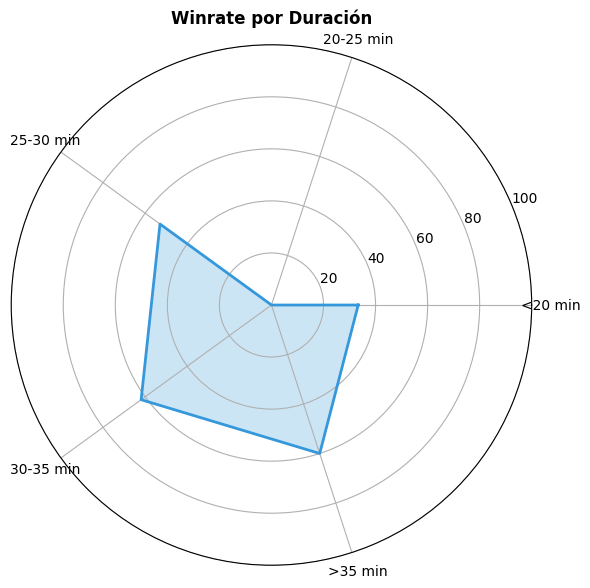

In [ ]:
# Winrate por duración de la partida (gráfico radial)
df_partidas["duracion_categoria"] = pd.cut(
    df_partidas["duracion_minutos"],
    bins=[0, 20, 25, 30, 35, 100],
    labels=["<20 min", "20-25 min", "25-30 min", "30-35 min", ">35 min"]
)

duracion_stats = df_partidas.groupby("duracion_categoria", observed=False).agg(
    winrate_pct=("win", lambda x: x.mean() * 100),
    partidas=("win", "count")
).round(2).rename(columns={"winrate_pct": "winrate_%"})

cat_dur = duracion_stats.index.astype(str).tolist()
vals_dur = duracion_stats["winrate_%"].fillna(0).tolist()
vals_dur = vals_dur + [vals_dur[0]]
ang_dur = np.linspace(0, 2 * np.pi, len(cat_dur), endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(6.5, 6), subplot_kw=dict(polar=True))
ax.plot(ang_dur, vals_dur, color="#3498db", linewidth=2)
ax.fill(ang_dur, vals_dur, color="#3498db", alpha=0.25)
ax.set_xticks(ang_dur[:-1])
ax.set_xticklabels(cat_dur, fontsize=10)
ax.set_ylim(0, 100)
ax.set_title("Winrate por Duración", pad=15, fontweight="bold")

plt.tight_layout()
plt.show()

###8.2 KDA

In [ ]:
kda_stats = pd.DataFrame({
    "Métrica": [
        "Kills promedio",
        "Deaths promedio",
        "Assists promedio",
        "KDA promedio"
    ],
    "Valor": [
        df_partidas["kills"].mean(),
        df_partidas["deaths"].mean(),
        df_partidas["assists"].mean(),
        df_partidas["kda"].mean()
    ]
})

display(kda_stats.round(2))

,Métrica,Valor
0,Kills promedio,4.01
1,Deaths promedio,6.09
2,Assists promedio,9.83
3,KDA promedio,3.15


In [ ]:
# Winrate de kda
df_partidas["KDA"] = pd.cut(
    df_partidas["kda"],
    bins=[-1, 2, 3.5, 5, 100],
    labels=["< 2", "2-3.5", "3.5-5", "> 5"]
)

kda_stats = df_partidas.groupby("KDA", observed=False).agg(
    winrate_pct=("win", lambda x: x.mean() * 100),
    partidas=("win", "count")
).round(2).rename(columns={"winrate_pct": "winrate_%"})

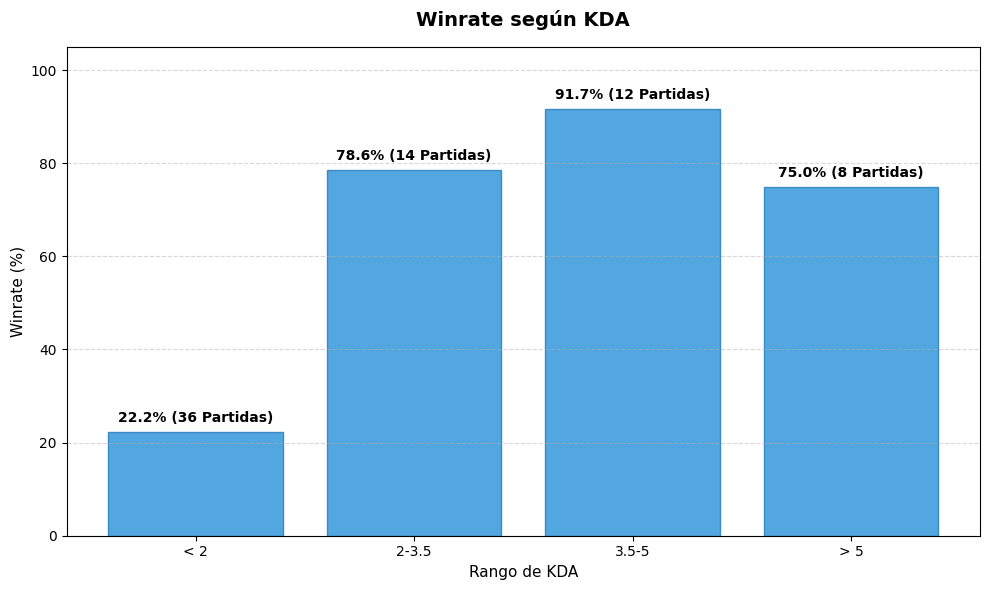

In [ ]:
kda_winrates = kda_stats['winrate_%']
kda_categories = kda_stats.index.astype(str)
kda_partidas = kda_stats['partidas']

plt.figure(figsize=(10, 6))
bars = plt.bar(
    kda_categories,
    kda_winrates,
    color='#3498db',
    edgecolor='#2980b9',
    alpha=0.85
)

for bar, num_partidas in zip(bars, kda_partidas):
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 1.5,
        f"{yval:.1f}% ({int(num_partidas)} Partidas)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

plt.title("Winrate según KDA", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Rango de KDA", fontsize=11)
plt.ylabel("Winrate (%)", fontsize=11)
plt.ylim(0, 105)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

###8.3 CS por minuto

In [ ]:
cs_stats = pd.DataFrame({
    "Métrica": [
        "CS/min promedio",
        "CS/min mediano",
        "CS/min mínimo",
        "CS/min máximo"
    ],
    "Valor": [
        df_partidas["cs_por_min"].mean(),
        df_partidas["cs_por_min"].median(),
        df_partidas["cs_por_min"].min(),
        df_partidas["cs_por_min"].max()
    ]
})

display(cs_stats.round(2))

,Métrica,Valor
0,CS/min promedio,1.99
1,CS/min mediano,1.54
2,CS/min mínimo,0.55
3,CS/min máximo,5.73


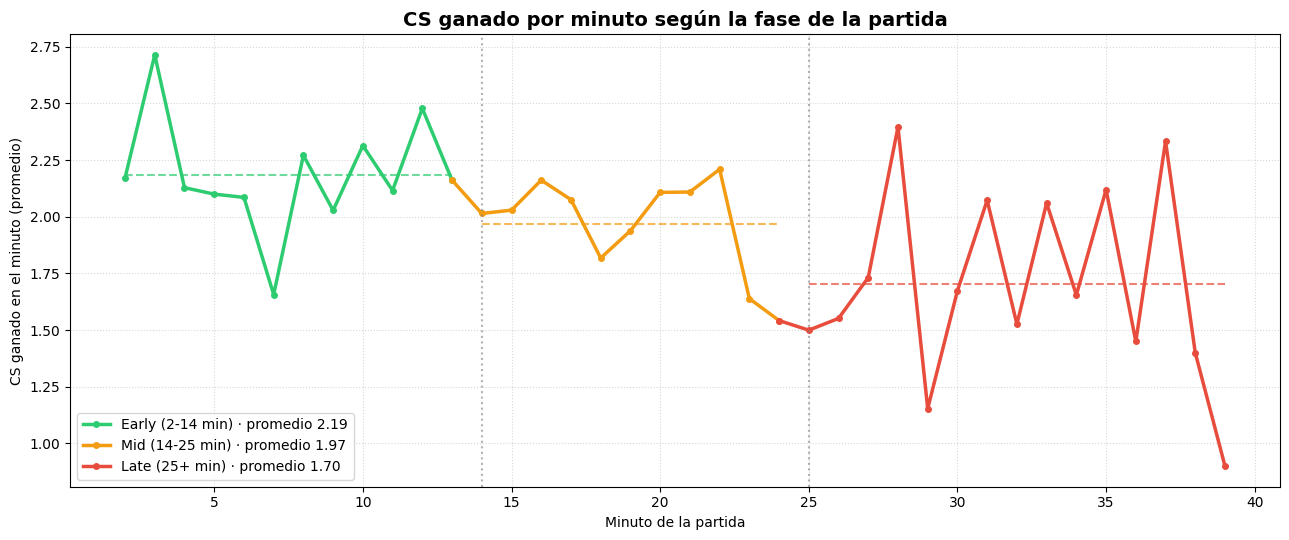

In [ ]:
# CS ganado por minuto a lo largo de la partida, comparando las fases
cs_fase = df_frames.sort_values(["match_id", "minuto"]).copy()
cs_fase["cs_minuto"] = cs_fase.groupby("match_id")["cs_total"].diff()      # CS ganado en cada minuto

# Solo minutos con muestra suficiente (>= 10 partidas).
# Se empieza en el minuto 2: en el minuto 1 aún no aparecen súbditos.
n_min = cs_fase.groupby("minuto")["match_id"].nunique()
cs_fase = cs_fase[cs_fase["minuto"].isin(n_min[n_min >= 10].index)]
cs_fase = cs_fase[cs_fase["minuto"] >= 2]

cs_min_prom = cs_fase.groupby("minuto")["cs_minuto"].mean()

fases_cs = {
    "Early (2-14 min)": (2, 14, "#2ecc71"),
    "Mid (14-25 min)":  (14, 25, "#f39c12"),
    "Late (25+ min)":   (25, 999, "#e74c3c"),
}

fig, ax = plt.subplots(figsize=(13, 5.5))

for nombre, (ini, fin, color) in fases_cs.items():
    # incluye el minuto anterior para que las líneas queden conectadas entre fases
    tramo = cs_min_prom[(cs_min_prom.index >= ini - 1) & (cs_min_prom.index < fin)]
    tramo_fase = cs_min_prom[(cs_min_prom.index >= ini) & (cs_min_prom.index < fin)]
    ax.plot(tramo.index, tramo.values, color=color, linewidth=2.5, marker="o", markersize=4,
            label=f"{nombre} · promedio {tramo_fase.mean():.2f}")
    ax.hlines(tramo_fase.mean(), tramo_fase.index.min(), tramo_fase.index.max(),
              colors=color, linestyles="--", alpha=0.7)

# Separadores de fase
for x in (14, 25):
    ax.axvline(x, color="gray", linestyle=":", alpha=0.6)

ax.set_title("CS ganado por minuto según la fase de la partida", fontsize=14, fontweight="bold")
ax.set_xlabel("Minuto de la partida")
ax.set_ylabel("CS ganado en el minuto (promedio)")
ax.grid(linestyle=":", alpha=0.5)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

###8.4 Oro por minuto

In [ ]:
oro_stats = pd.DataFrame({
    "Métrica": [
        "Oro/min promedio",
        "Oro/min mediano",
        "Oro/min mínimo",
        "Oro/min máximo"
    ],
    "Valor": [
        df_partidas["gold_por_min"].mean(),
        df_partidas["gold_por_min"].median(),
        df_partidas["gold_por_min"].min(),
        df_partidas["gold_por_min"].max()
    ]
})

display(oro_stats.round(2))

,Métrica,Valor
0,Oro/min promedio,316.64
1,Oro/min mediano,309.32
2,Oro/min mínimo,188.54
3,Oro/min máximo,448.12


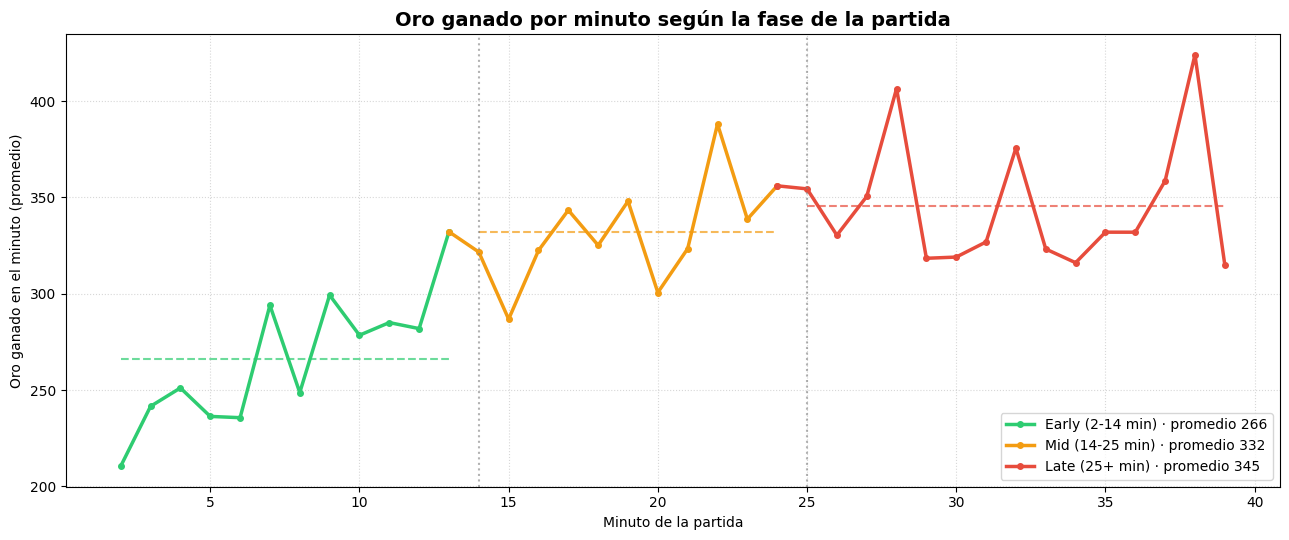

In [ ]:
# Oro ganado por minuto a lo largo de la partida, comparando las fases
oro_fase = df_frames.sort_values(["match_id", "minuto"]).copy()
oro_fase["oro_minuto"] = oro_fase.groupby("match_id")["total_gold"].diff()   # oro ganado en cada minuto

# Solo minutos con muestra suficiente (>= 10 partidas), desde el minuto 2
n_min = oro_fase.groupby("minuto")["match_id"].nunique()
oro_fase = oro_fase[oro_fase["minuto"].isin(n_min[n_min >= 10].index)]
oro_fase = oro_fase[oro_fase["minuto"] >= 2]

oro_min_prom = oro_fase.groupby("minuto")["oro_minuto"].mean()

fases_oro = {
    "Early (2-14 min)": (2, 14, "#2ecc71"),
    "Mid (14-25 min)":  (14, 25, "#f39c12"),
    "Late (25+ min)":   (25, 999, "#e74c3c"),
}

fig, ax = plt.subplots(figsize=(13, 5.5))

for nombre, (ini, fin, color) in fases_oro.items():
    # incluye el minuto anterior para que las líneas queden conectadas entre fases
    tramo = oro_min_prom[(oro_min_prom.index >= ini - 1) & (oro_min_prom.index < fin)]
    tramo_fase = oro_min_prom[(oro_min_prom.index >= ini) & (oro_min_prom.index < fin)]
    ax.plot(tramo.index, tramo.values, color=color, linewidth=2.5, marker="o", markersize=4,
            label=f"{nombre} · promedio {tramo_fase.mean():.0f}")
    ax.hlines(tramo_fase.mean(), tramo_fase.index.min(), tramo_fase.index.max(),
              colors=color, linestyles="--", alpha=0.7)

# Separadores de fase
for x in (14, 25):
    ax.axvline(x, color="gray", linestyle=":", alpha=0.6)

ax.set_title("Oro ganado por minuto según la fase de la partida", fontsize=14, fontweight="bold")
ax.set_xlabel("Minuto de la partida")
ax.set_ylabel("Oro ganado en el minuto (promedio)")
ax.grid(linestyle=":", alpha=0.5)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

###8.5 Daño

In [ ]:
daño_stats = pd.DataFrame({
    "Métrica": [
        "Daño promedio",
        "Daño mediano",
        "Daño mínimo",
        "Daño máximo"
    ],
    "Valor": [
        df_partidas["damage_dealt"].mean(),
        df_partidas["damage_dealt"].median(),
        df_partidas["damage_dealt"].min(),
        df_partidas["damage_dealt"].max()
    ]
})

display(daño_stats.round(2))

,Métrica,Valor
0,Daño promedio,14659.33
1,Daño mediano,12777.00
2,Daño mínimo,1186.00
3,Daño máximo,60054.00


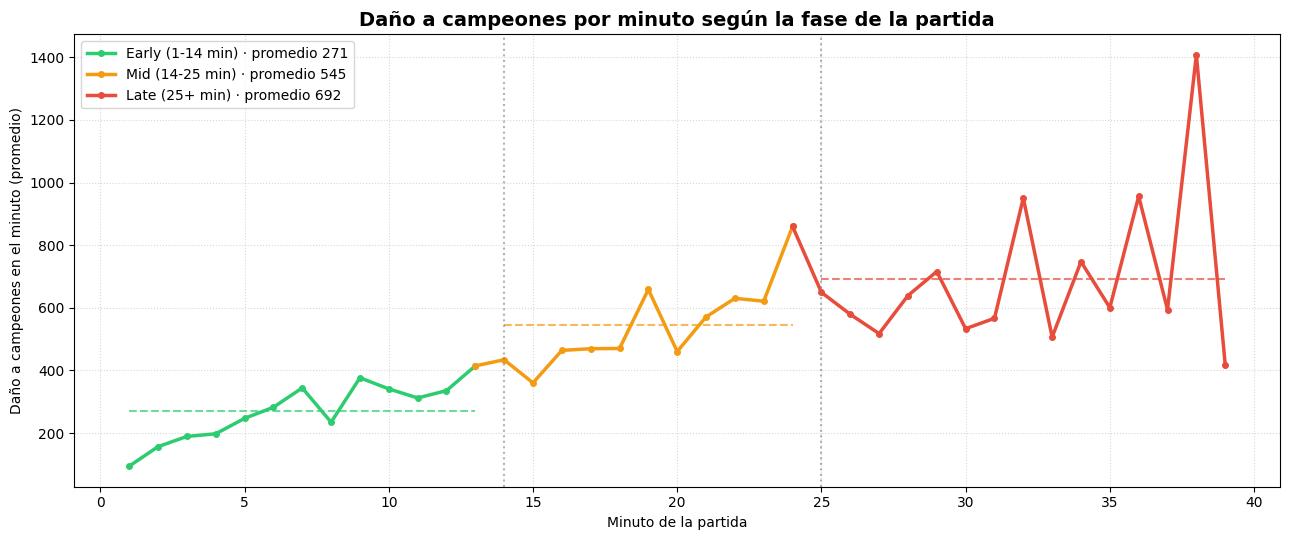

In [ ]:
# Daño a campeones por minuto a lo largo de la partida, comparando las fases
dano_fase = df_frames.sort_values(["match_id", "minuto"]).copy()
dano_fase["dano_minuto"] = dano_fase.groupby("match_id")["dmg_totalDamageDoneToChampions"].diff()

# Solo minutos con muestra suficiente (>= 10 partidas), desde el minuto 1
n_min = dano_fase.groupby("minuto")["match_id"].nunique()
dano_fase = dano_fase[dano_fase["minuto"].isin(n_min[n_min >= 10].index)]
dano_fase = dano_fase[dano_fase["minuto"] >= 1]

dano_min_prom = dano_fase.groupby("minuto")["dano_minuto"].mean()

fases_dano = {
    "Early (1-14 min)": (1, 14, "#2ecc71"),
    "Mid (14-25 min)":  (14, 25, "#f39c12"),
    "Late (25+ min)":   (25, 999, "#e74c3c"),
}

fig, ax = plt.subplots(figsize=(13, 5.5))

for nombre, (ini, fin, color) in fases_dano.items():
    # incluye el minuto anterior para que las líneas queden conectadas entre fases
    tramo = dano_min_prom[(dano_min_prom.index >= ini - 1) & (dano_min_prom.index < fin)]
    tramo_fase = dano_min_prom[(dano_min_prom.index >= ini) & (dano_min_prom.index < fin)]
    ax.plot(tramo.index, tramo.values, color=color, linewidth=2.5, marker="o", markersize=4,
            label=f"{nombre} · promedio {tramo_fase.mean():.0f}")
    ax.hlines(tramo_fase.mean(), tramo_fase.index.min(), tramo_fase.index.max(),
              colors=color, linestyles="--", alpha=0.7)

# Separadores de fase
for x in (14, 25):
    ax.axvline(x, color="gray", linestyle=":", alpha=0.6)

ax.set_title("Daño a campeones por minuto según la fase de la partida", fontsize=14, fontweight="bold")
ax.set_xlabel("Minuto de la partida")
ax.set_ylabel("Daño a campeones en el minuto (promedio)")
ax.grid(linestyle=":", alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

###8.6 Visión (wards)

In [ ]:
vision_stats = pd.DataFrame({
    "Métrica": [
        "Wards colocados promedio",
        "Wards colocados mediano",
        "Wards colocados mínimo",
        "Wards colocados máximo",
        "Wards destruidos promedio",
        "Wards destruidos mediano",
        "Wards destruidos mínimo",
        "Wards destruidos máximo"
    ],
    "Valor": [
        df_partidas["wards_placed"].mean(),
        df_partidas["wards_placed"].median(),
        df_partidas["wards_placed"].min(),
        df_partidas["wards_placed"].max(),
        df_partidas["wards_killed"].mean(),
        df_partidas["wards_killed"].median(),
        df_partidas["wards_killed"].min(),
        df_partidas["wards_killed"].max()
    ]
})

display(vision_stats.round(2))

,Métrica,Valor
0,Wards colocados promedio,17.39
1,Wards colocados mediano,19.00
2,Wards colocados mínimo,2.00
3,Wards colocados máximo,32.00
4,Wards destruidos promedio,5.60
5,Wards destruidos mediano,5.50
6,Wards destruidos mínimo,0.00
7,Wards destruidos máximo,25.00


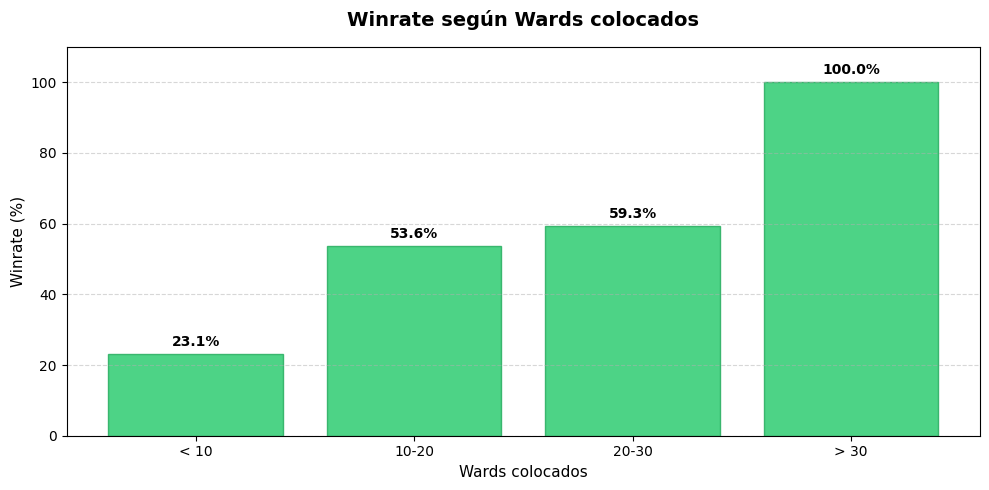

In [ ]:
# 1. Crear las categorías de wards colocados
df_partidas["vision"] = pd.cut(
    df_partidas["wards_placed"],
    bins=[-1, 10, 20, 30, 1000],
    labels=["< 10", "10-20", "20-30", "> 30"]
)

# 2. Agrupar para obtener el winrate (%) y cantidad de partidas por categoría
vision_winrate_df = df_partidas.groupby("vision", observed=False).agg(
    winrate_pct=("win", lambda x: x.mean() * 100),
    partidas=("win", "count")
).round(2).rename(columns={"winrate_pct": "winrate_%"})

# 3. Obtener categorías y winrates
categorias_vision = vision_winrate_df.index.astype(str)
winrate_vision = vision_winrate_df['winrate_%']

plt.figure(figsize=(10, 5))

bars = plt.bar(
    categorias_vision,
    winrate_vision,
    color='#2ecc71',
    edgecolor='#27ae60',
    alpha=0.85
)

# Agregar etiquetas de porcentaje arriba de cada barra
for bar in bars:
    yval = bar.get_height()
    if not np.isnan(yval):
        plt.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + 1.5,
            f"{yval:.1f}%",
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

plt.title("Winrate según Wards colocados", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Wards colocados", fontsize=11)
plt.ylabel("Winrate (%)", fontsize=11)
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

###8.7 Kills

In [ ]:
kills_stats = pd.DataFrame({
    "Métrica": [
        "Kills promedio",
        "Kills mediano",
        "Kills mínimo",
        "Kills máximo"
    ],
    "Valor": [
        df_partidas["kills"].mean(),
        df_partidas["kills"].median(),
        df_partidas["kills"].min(),
        df_partidas["kills"].max()
    ]
})

display(kills_stats.round(2))

,Métrica,Valor
0,Kills promedio,4.01
1,Kills mediano,3.00
2,Kills mínimo,0.00
3,Kills máximo,17.00


In [ ]:
# Winrate kills
df_partidas["asesinatos"] = pd.cut(
    df_partidas["kills"],
    bins=[-1, 3, 6, 10, 100],
    labels=["< 3", "3-6", "6-10", "> 10"]
)

kills_stats = df_partidas.groupby("asesinatos", observed=False).agg(
    winrate_pct=("win", lambda x: x.mean() * 100),
    partidas=("win", "count")
).round(2).rename(columns={"winrate_pct": "winrate_%"})

kills_stats

,winrate_%,partidas
asesinatos,,
< 3,40.54,37
3-6,57.89,19
6-10,81.82,11
> 10,33.33,3


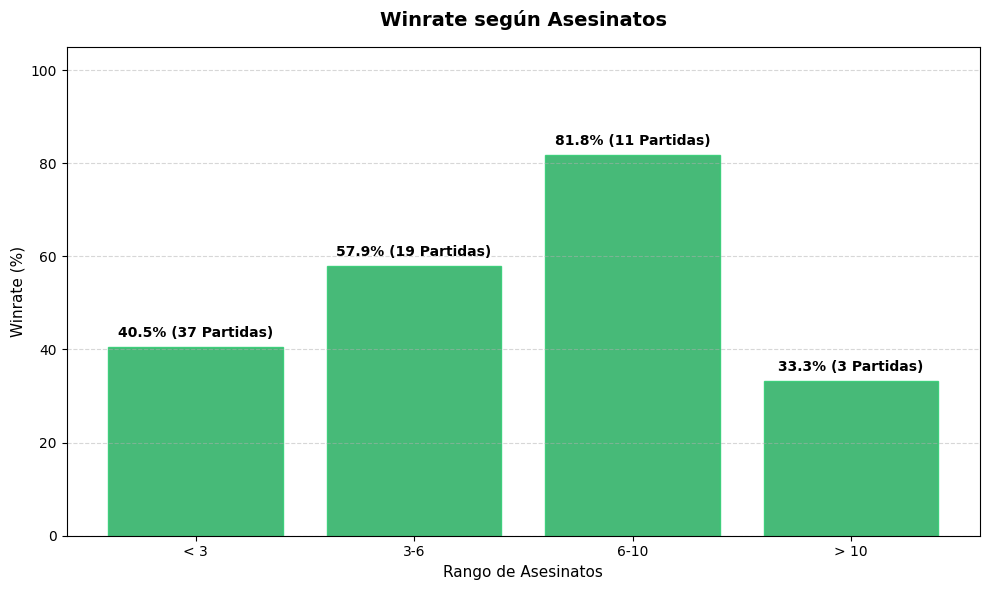

In [ ]:
kills_winrates = kills_stats['winrate_%']
kills_categories = kills_stats.index.astype(str)
kills_partidas = kills_stats['partidas']

plt.figure(figsize=(10, 6))
bars = plt.bar(
    kills_categories,
    kills_winrates,
    color='#27ae60', # Un color verde diferente
    edgecolor='#2ecc71',
    alpha=0.85
)

# Añadir etiquetas de valor y número de partidas sobre cada barra
for bar, num_partidas in zip(bars, kills_partidas):
    yval = bar.get_height()
    if not pd.isna(yval): # Verificar si el valor no es NaN antes de mostrar
        plt.text(
            bar.get_x() + bar.get_width()/2,
            yval + 1.5,
            f"{yval:.1f}% ({int(num_partidas)} Partidas)",
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

plt.title("Winrate según Asesinatos", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Rango de Asesinatos", fontsize=11)
plt.ylabel("Winrate (%)", fontsize=11)
plt.ylim(0, 105) # Ajustar el límite y para acomodar las etiquetas
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

###8.8 Asistencias

In [ ]:
assists_stats = pd.DataFrame({
    "Métrica": [
        "Asistencias promedio",
        "Asistencias mediano",
        "Asistencias mínimo",
        "Asistencias máximo"
    ],
    "Valor": [
        df_partidas["assists"].mean(),
        df_partidas["assists"].median(),
        df_partidas["assists"].min(),
        df_partidas["assists"].max()
    ]
})

display(assists_stats.round(2))

,Métrica,Valor
0,Asistencias promedio,9.83
1,Asistencias mediano,9.00
2,Asistencias mínimo,0.00
3,Asistencias máximo,25.00


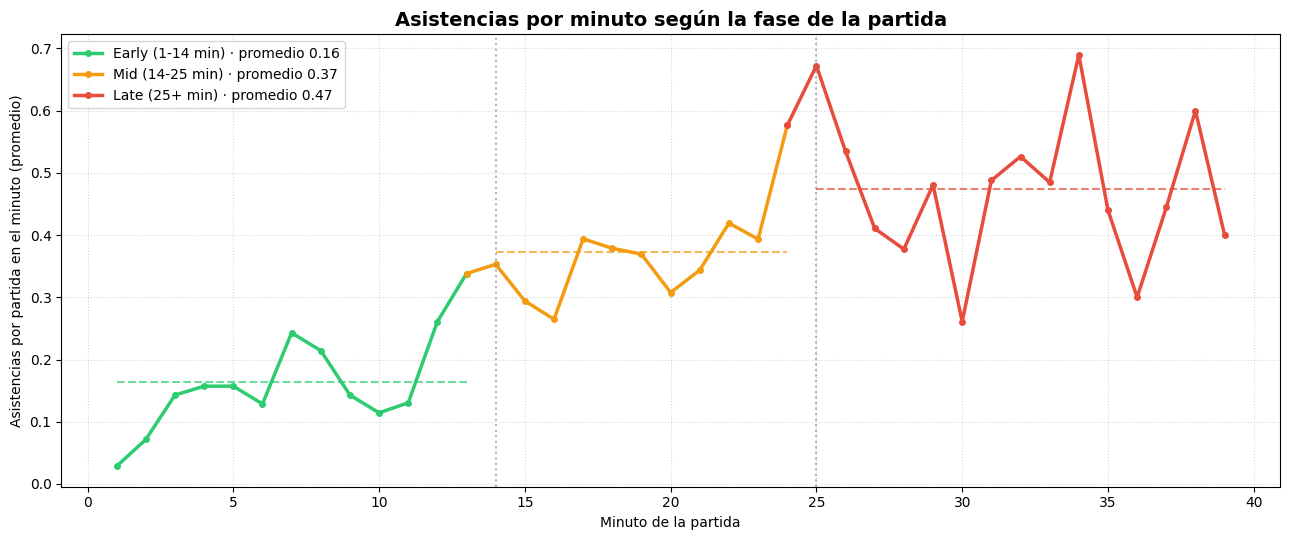

In [ ]:
import ast

# Asistencias del jugador por minuto (eventos CHAMPION_KILL donde figura como asistente)
ev_asist = pd.read_csv(
    "/content/drive/MyDrive/Ciencia De Datos/lol/timeline_events.csv",
    usecols=["match_id", "minuto", "type", "assistingParticipantIds"]
)
ev_asist = ev_asist[ev_asist["type"] == "CHAMPION_KILL"].merge(
    df_frames.drop_duplicates("match_id")[["match_id", "participant_id"]], on="match_id"
)
ev_asist["asistio"] = [
    (p in ast.literal_eval(a)) if isinstance(a, str) else False
    for p, a in zip(ev_asist["participant_id"], ev_asist["assistingParticipantIds"])
]
asist_por_minuto = ev_asist[ev_asist["asistio"]].groupby("minuto").size()

# Partidas que siguen en curso en cada minuto (solo minutos con >= 10 partidas)
partidas_min = df_frames.groupby("minuto")["match_id"].nunique()
partidas_min = partidas_min[partidas_min >= 10]
partidas_min = partidas_min[partidas_min.index >= 1]

# Asistencias promedio por partida en cada minuto
asist_prom = (asist_por_minuto.reindex(partidas_min.index, fill_value=0) / partidas_min)

fases_asist = {
    "Early (1-14 min)": (1, 14, "#2ecc71"),
    "Mid (14-25 min)":  (14, 25, "#f39c12"),
    "Late (25+ min)":   (25, 999, "#e74c3c"),
}

fig, ax = plt.subplots(figsize=(13, 5.5))

for nombre, (ini, fin, color) in fases_asist.items():
    # incluye el minuto anterior para que las líneas queden conectadas entre fases
    tramo = asist_prom[(asist_prom.index >= ini - 1) & (asist_prom.index < fin)]
    tramo_fase = asist_prom[(asist_prom.index >= ini) & (asist_prom.index < fin)]
    ax.plot(tramo.index, tramo.values, color=color, linewidth=2.5, marker="o", markersize=4,
            label=f"{nombre} · promedio {tramo_fase.mean():.2f}")
    ax.hlines(tramo_fase.mean(), tramo_fase.index.min(), tramo_fase.index.max(),
              colors=color, linestyles="--", alpha=0.7)

# Separadores de fase
for x in (14, 25):
    ax.axvline(x, color="gray", linestyle=":", alpha=0.6)

ax.set_title("Asistencias por minuto según la fase de la partida", fontsize=14, fontweight="bold")
ax.set_xlabel("Minuto de la partida")
ax.set_ylabel("Asistencias por partida en el minuto (promedio)")
ax.grid(linestyle=":", alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

###8.9 Gráfico radial

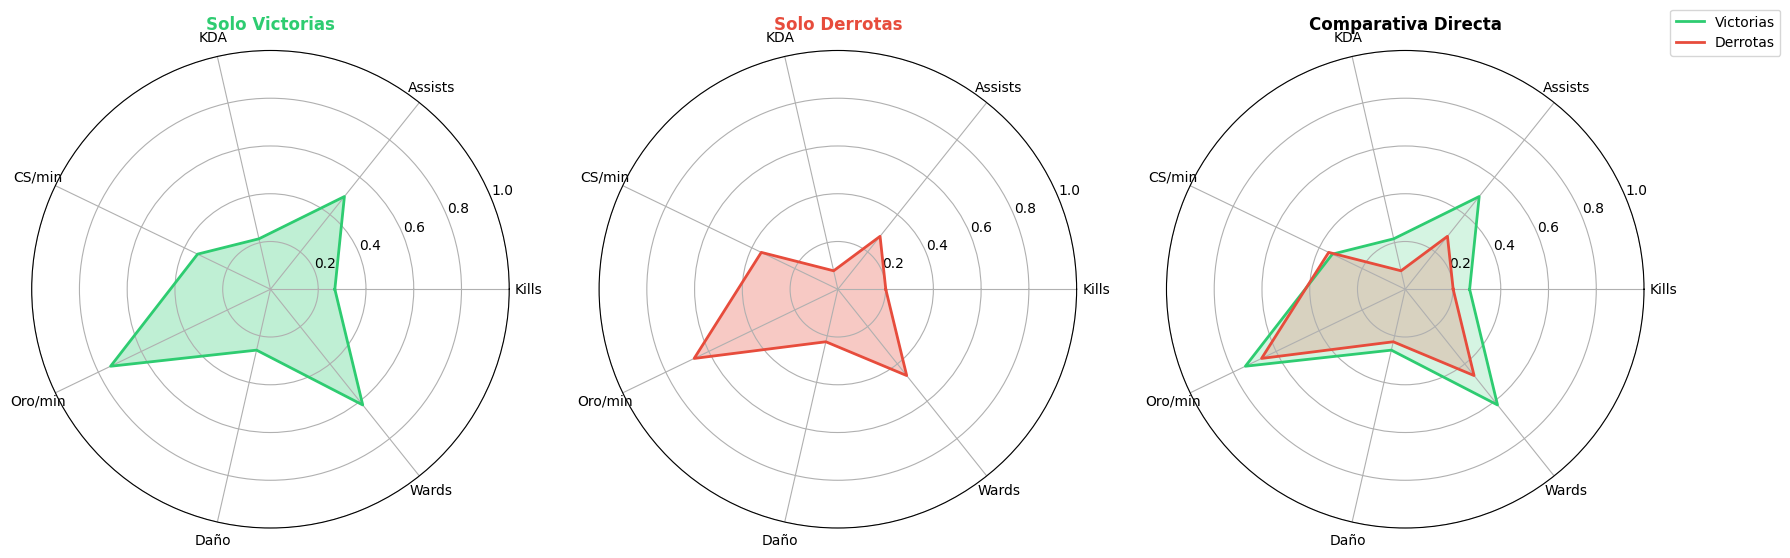

In [ ]:
# Promedio de cada estadística dividido entre su máximo histórico (escala de 0 a 1).

cols = ["kills", "assists", "kda", "cs_por_min", "gold_por_min", "damage_dealt", "wards_placed"]
labels = ["Kills", "Assists", "KDA", "CS/min", "Oro/min", "Daño", "Wards"]

stats = df_partidas.groupby("win")[cols].mean() / df_partidas[cols].max()

angulos = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist()
angulos += angulos[:1]

vals_win = stats.loc[True].tolist() + [stats.loc[True].iloc[0]]
vals_loss = stats.loc[False].tolist() + [stats.loc[False].iloc[0]]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5), subplot_kw=dict(polar=True))

# --- Gráfica 1: SOLO VICTORIAS ---
ax1.plot(angulos, vals_win, color="#2ecc71", linewidth=2)
ax1.fill(angulos, vals_win, color="#2ecc71", alpha=0.3)
ax1.set_xticks(angulos[:-1])
ax1.set_xticklabels(labels)
ax1.set_ylim(0, 1)
ax1.set_title("Solo Victorias", pad=15, color="#2ecc71", fontweight="bold")

# --- Gráfica 2: SOLO DERROTAS ---
ax2.plot(angulos, vals_loss, color="#e74c3c", linewidth=2)
ax2.fill(angulos, vals_loss, color="#e74c3c", alpha=0.3)
ax2.set_xticks(angulos[:-1])
ax2.set_xticklabels(labels)
ax2.set_ylim(0, 1)
ax2.set_title("Solo Derrotas", pad=15, color="#e74c3c", fontweight="bold")

# --- Gráfica 3: JUNTAS (COMPARACIÓN DIRECTA) ---
ax3.plot(angulos, vals_win, color="#2ecc71", linewidth=2, label="Victorias")
ax3.fill(angulos, vals_win, color="#2ecc71", alpha=0.2)
ax3.plot(angulos, vals_loss, color="#e74c3c", linewidth=2, label="Derrotas")
ax3.fill(angulos, vals_loss, color="#e74c3c", alpha=0.2)
ax3.set_xticks(angulos[:-1])
ax3.set_xticklabels(labels)
ax3.set_ylim(0, 1)
ax3.set_title("Comparativa Directa", pad=15, fontweight="bold")
ax3.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()

###8.10 Rendimiento según la hora del día
`timeline_frames` no trae la fecha de la partida, así que la hora sale de la columna `fecha` de `matches_2026.csv` (se une por `match_id`). La tabla muestra, para cada hora en la que el jugador ha jugado, las partidas, el winrate y el promedio de KDA, CS por minuto y daño. Las horas con pocas partidas no son concluyentes.

In [252]:
# Winrate y rendimiento según la hora a la que juega
# (usa matches_2026, cargado en la sección 3.5)
horas = df_partidas.merge(matches_2026[["match_id", "fecha"]], on="match_id", how="inner")
horas["hora"] = horas["fecha"].dt.hour
print(f"Partidas con hora: {len(horas)} de {len(df_partidas)}")

por_hora = horas.groupby("hora").agg(
    partidas=("win", "size"), victorias=("win", "sum"),
    kda=("kda", "mean"), cs_por_min=("cs_por_min", "mean"), damage_dealt=("damage_dealt", "mean"))
por_hora["derrotas"] = por_hora["partidas"] - por_hora["victorias"]
por_hora["winrate_%"] = por_hora["victorias"] / por_hora["partidas"] * 100
por_hora = por_hora[["partidas", "victorias", "derrotas", "winrate_%", "kda", "cs_por_min", "damage_dealt"]].round(2)
por_hora.index = [f"{h:02d}:00" for h in por_hora.index]
por_hora.index.name = "hora"

display(por_hora)


Partidas con hora: 70 de 70


,partidas,victorias,derrotas,winrate_%,kda,cs_por_min,damage_dealt
hora,,,,,,,
01:00,1,0,1,0.00,0.88,1.86,6272.00
06:00,1,0,1,0.00,2.62,1.15,22260.00
07:00,3,2,1,66.67,3.94,1.78,25826.00
08:00,4,2,2,50.00,1.87,1.06,7810.00
09:00,6,5,1,83.33,3.50,1.60,10313.17
10:00,1,0,1,0.00,0.40,5.38,7737.00
11:00,2,0,2,0.00,1.90,1.90,16513.50
12:00,1,0,1,0.00,1.14,1.31,8568.00
13:00,8,5,3,62.50,2.71,1.80,12956.50


###9. Campeones más jugados
Los 5 campeones con más partidas del jugador.

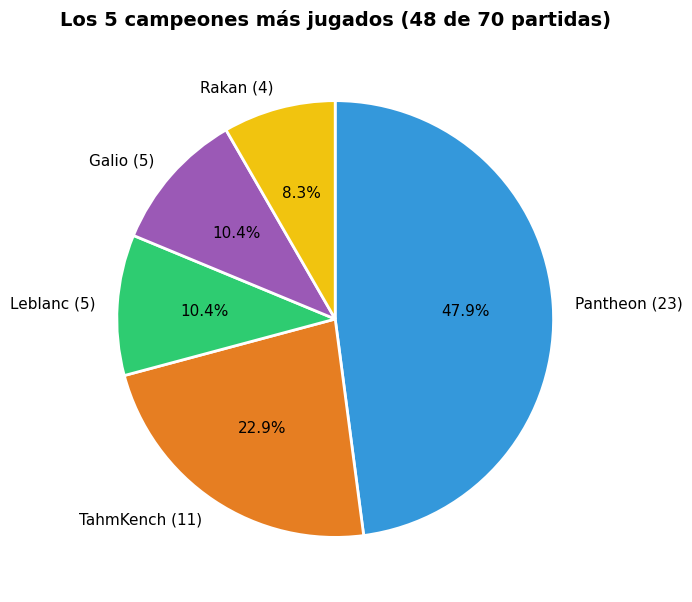

In [ ]:
# Una fila por partida (se usa también en 7.1 y en la sección 8)
tabla_partidas = df_frames.groupby("match_id").agg(
    champion=("champion", "first"),
    position=("position", "first"),
    win=("win", "first")
)

# Los 5 campeones más jugados en diagrama de torta
top5 = tabla_partidas["champion"].value_counts().head(5)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    top5.values,
    labels=[f"{c} ({n})" for c, n in top5.items()],
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    counterclock=False,
    colors=["#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#f1c40f"],
    wedgeprops=dict(edgecolor="white", linewidth=2),
    textprops=dict(fontsize=11)
)
ax.set_title(f"Los 5 campeones más jugados ({top5.sum()} de {len(tabla_partidas)} partidas)",
             fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

###9.1 Winrate de los 2 campeones más jugados
Para cada uno de los 2 campeones más jugados, un diagrama de torta con su proporción de victorias y derrotas.

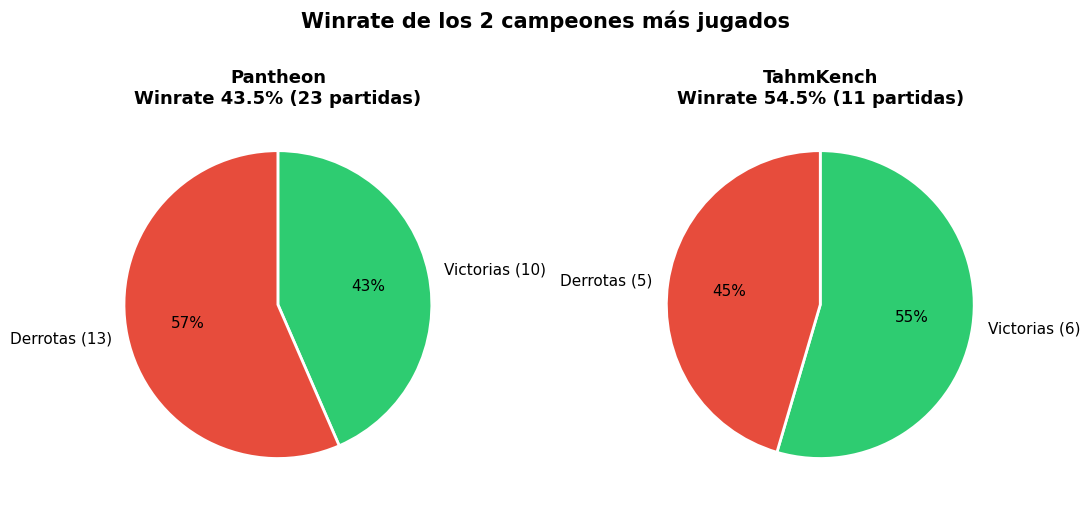

In [ ]:
top2 = top5.head(2)

fig, axes = plt.subplots(1, len(top2), figsize=(5.5 * len(top2), 5.5))

for ax, campeon in zip(axes, top2.index):
    d = tabla_partidas[tabla_partidas["champion"] == campeon]
    victorias = int(d["win"].sum())
    derrotas = len(d) - victorias
    winrate = victorias / len(d) * 100

    ax.pie(
        [victorias, derrotas],
        labels=[f"Victorias ({victorias})", f"Derrotas ({derrotas})"],
        colors=["#2ecc71", "#e74c3c"],
        autopct=lambda p: f"{p:.0f}%" if p > 0 else "",
        startangle=90,
        counterclock=False,
        wedgeprops=dict(edgecolor="white", linewidth=2),
        textprops=dict(fontsize=11)
    )
    ax.set_title(f"{campeon}\nWinrate {winrate:.1f}% ({len(d)} partidas)",
                 fontsize=13, fontweight="bold")

fig.suptitle("Winrate de los 2 campeones más jugados", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

###9.2 Winrate y estadísticas de los 2 campeones más jugados
Tabla con las partidas, el winrate y el promedio de kills, deaths, assists, KDA, CS por minuto y daño a campeones de cada uno de los 2 campeones más jugados.

In [244]:
#Winrate y estadisticas de los 2 campeones mas jugados
metricas = ["kills", "deaths", "assists", "kda", "cs_por_min", "damage_dealt"]

top2_nombres = df_partidas["champion"].value_counts().head(2).index

campeones_stats = (df_partidas[df_partidas["champion"].isin(top2_nombres)]
    .groupby("champion").agg(
        partidas=("win", "size"),
        victorias=("win", "sum"),
        **{m: (m, "mean") for m in metricas}
    ))
campeones_stats["winrate_%"] = campeones_stats["victorias"] / campeones_stats["partidas"] * 100
campeones_stats = (campeones_stats[["partidas", "victorias", "winrate_%"] + metricas]
                   .sort_values("partidas", ascending=False).round(2))

display(campeones_stats)


,partidas,victorias,winrate_%,kills,deaths,assists,kda,cs_por_min,damage_dealt
champion,,,,,,,,,
Pantheon,23,10,43.48,5.78,7.35,9.48,3.05,2.00,18858.00
TahmKench,11,6,54.55,4.45,3.36,6.00,3.70,3.47,16945.36


###9.3 Mapas de calor de los 2 campeones más jugados
Un mapa de calor por campeón, con una celda para cada uno. Cada mapa separa las tres fases (Early, Mid y Late) y se ve siempre desde el lado azul: las partidas del equipo rojo se espejan.

###9.3.1 Preparación (función del mapa de calor)

In [234]:
# Función reutilizable: mapa de calor por fase de un campeón
from scipy.ndimage import gaussian_filter
import matplotlib.image as mpimg
from matplotlib.colors import LinearSegmentedColormap

MIN_X, MAX_X = -120, 14870
MIN_Y, MAX_Y = -120, 14980
PUNTOS, SALTO_MAX, BINS = 6, 5000, 250
fases = {"Early (1-14 min)": (1, 14), "Mid (14-25 min)": (14, 25), "Late (25+ min)": (25, 999)}
BG, CARD = "#14141A", "#1C1C24"
extent = [MIN_X, MAX_X, MIN_Y, MAX_Y]
mapa = mpimg.imread("/content/drive/MyDrive/Ciencia De Datos/lol/Mapa lol.png")
paleta = LinearSegmentedColormap.from_list("heat", ["#6B21FF", "#C026D3", "#FB923C", "#FDE047", "#FFFBEB"])

top2_champs = tabla_partidas["champion"].value_counts().head(2).index.tolist()

# Tramos entre frames consecutivos, solo con el jugador vivo
f_mapa = df_frames.sort_values(["match_id", "minuto"]).copy()
sig = f_mapa.groupby("match_id")[["minuto", "pos_x", "pos_y", "champ_health"]].shift(-1)
f_mapa["x1"], f_mapa["y1"], f_mapa["min_sig"] = sig["pos_x"], sig["pos_y"], sig["minuto"]
f_mapa["vivo_sig"] = sig["champ_health"] > 0
f_mapa = f_mapa[(f_mapa["minuto"] > 0) & (f_mapa["champ_health"] > 0)]

def espejar(x, y, rojo):  # todo visto desde el lado azul
    return (np.where(rojo, MAX_X + MIN_X - x, x), np.where(rojo, MAX_Y + MIN_Y - y, y))

def puntos_fase(d):
    rojo = (d["team_id"] == 200).to_numpy()
    x0, y0 = espejar(d["pos_x"].to_numpy(float), d["pos_y"].to_numpy(float), rojo)
    x1, y1 = espejar(d["x1"].to_numpy(float), d["y1"].to_numpy(float), rojo)
    ok = d["vivo_sig"].to_numpy() & (d["min_sig"].to_numpy() == d["minuto"].to_numpy() + 1)
    ok &= np.hypot(x1 - x0, y1 - y0) < SALTO_MAX
    xs, ys = [x0], [y0]
    for t in np.linspace(0, 1, PUNTOS, endpoint=False)[1:]:
        xs.append((x0 + (x1 - x0) * t)[ok]); ys.append((y0 + (y1 - y0) * t)[ok])
    return np.concatenate(xs), np.concatenate(ys)

def mapa_calor_campeon(champ):
    fc = f_mapa[f_mapa["champion"] == champ]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), facecolor=BG)
    for ax, (nombre, (m_ini, m_fin)) in zip(axes, fases.items()):
        ax.set_facecolor(CARD)
        ax.imshow(mapa, extent=extent, aspect="equal", alpha=0.5, zorder=0)
        d = fc[(fc["minuto"] >= m_ini) & (fc["minuto"] < m_fin)]
        x, y = puntos_fase(d)
        if len(x) > 0:
            H, _, _ = np.histogram2d(x, y, bins=BINS, range=[[MIN_X, MAX_X], [MIN_Y, MAX_Y]])
            H = gaussian_filter(H.T, sigma=3)
            H = H / H.max()
            rgba = paleta(H)
            rgba[..., 3] = np.clip(H / 0.10, 0, 1) * 0.95
            ax.imshow(rgba, extent=extent, origin="lower", aspect="equal",
                      interpolation="bilinear", zorder=1)
        ax.set_xlim(MIN_X, MAX_X); ax.set_ylim(MIN_Y, MAX_Y); ax.axis("off")
        ax.set_title(nombre, color="white", fontsize=14, fontweight="bold", pad=8)
        ax.text(0.5, -0.02, f"{len(d)} frames · {d['match_id'].nunique()} partidas",
                color="#9CA3AF", fontsize=10, ha="center", va="top", transform=ax.transAxes)
    fig.suptitle(f"Mapa de calor por fase — {champ}", color="white", fontsize=17, fontweight="bold", y=0.99)
    plt.tight_layout(rect=[0, 0.01, 1, 0.94])
    plt.show()

print("Campeones:", top2_champs)


Campeones: ['Pantheon', 'TahmKench']


###9.3.2 Mapa de calor del campeón más jugado

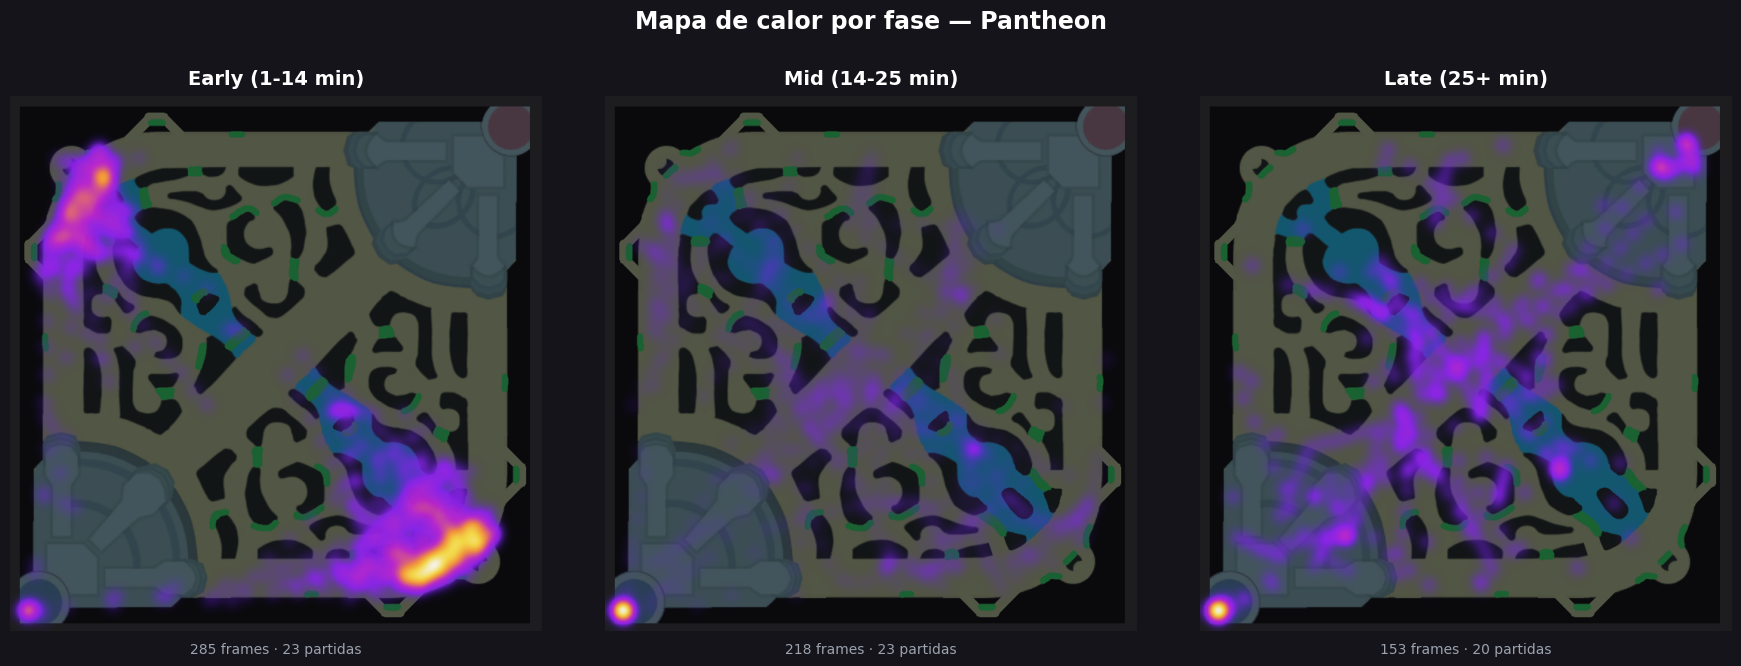

In [235]:
mapa_calor_campeon(top2_champs[0])


###9.3.3 Mapa de calor del segundo campeón más jugado

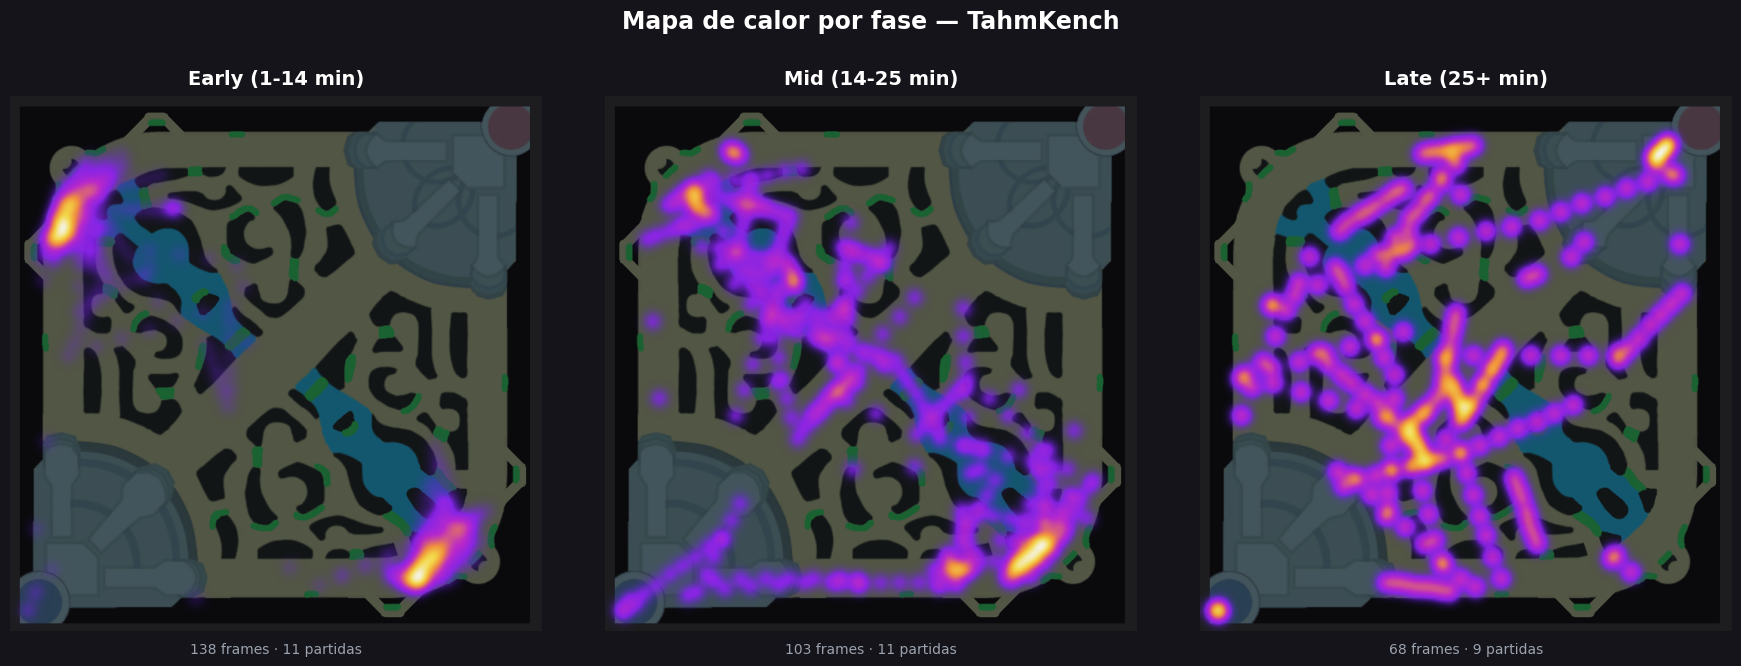

In [237]:
mapa_calor_campeon(top2_champs[1])

###10. Posiciones más jugadas
Distribución de las partidas del jugador por posición.

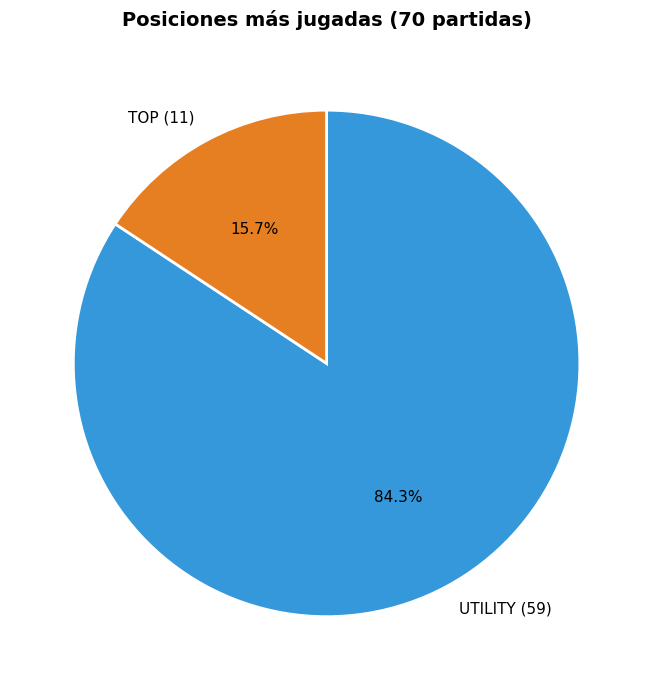

In [238]:
# Posiciones más jugadas en diagrama de torta
posiciones = tabla_partidas["position"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    posiciones.values,
    labels=[f"{p} ({n})" for p, n in posiciones.items()],
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    counterclock=False,
    colors=["#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#f1c40f"][:len(posiciones)],
    wedgeprops=dict(edgecolor="white", linewidth=2),
    textprops=dict(fontsize=11)
)
ax.set_title(f"Posiciones más jugadas ({len(tabla_partidas)} partidas)",
             fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

###10.2 Rendimiento según posición

In [239]:
rendimiento_posicion = df_partidas.groupby("position").agg(
    partidas=("match_id", "count"),
    victorias=("win", "sum"),
    winrate=("win", "mean"),
    kda_promedio=("kda", "mean"),
    cs_min_promedio=("cs_por_min", "mean"),
    oro_min_promedio=("gold_por_min", "mean"),
    wards_promedio=("wards_placed", "mean")
).reset_index()

rendimiento_posicion["winrate"] *= 100

rendimiento_posicion.sort_values(
    "partidas",
    ascending=False
)

,position,partidas,victorias,winrate,kda_promedio,cs_min_promedio,oro_min_promedio,wards_promedio
1,UTILITY,59,31,52.542373,3.274646,1.528992,319.348487,19.118644
0,TOP,11,5,45.454545,2.479221,4.448200,302.138436,8.090909


In [240]:
total_minutos = df_partidas['duracion_minutos'].sum()
horas_totales = total_minutos / 60

print(f"El jugador ha acumulado un total de {horas_totales:.2f} horas de juego.")

El jugador ha acumulado un total de 36.08 horas de juego.
